# Лабораторная работа 4 - Метод главных компонент (PCA)

На основе варианта создать датасет.

Вариант 2, $N = 1000$:

- $X_1$ - равномерно от 0 до 10
- $X_2$ - равномерно от 0 до 10
- $X_3 = X_1 + X_2 + \varepsilon$, где $\varepsilon$ - нормальный шум со средним 0 и дисперсией 5
- $X_4$ - нормально со средним 10 и дисперсией 9
- $X_5 = 2X_4 + \varepsilon$, где $\varepsilon$ - нормальный шум со средним 1 и дисперсией 3
- $X_6$ - экспоненциально с $\lambda = 0.5$
- $X_7 = \sqrt{X_6}$
- $X_8$ - бинарная переменная со значениями 0 или 1, закон распределения равномерный

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

N = 1000
X1 = np.random.uniform(0, 10, N)
X2 = np.random.uniform(0, 10, N)
X3 = X1 + X2 + np.random.normal(0, np.sqrt(5), N)
X4 = np.random.normal(10, np.sqrt(9), N)
X5 = 2 * X4 + np.random.normal(1, np.sqrt(3), N)
X6 = np.random.exponential(1 / 0.5, N)
X7 = np.sqrt(X6)
X8 = np.random.randint(0, 2, N)

df = pd.DataFrame({"X1": X1, "X2": X2, "X3": X3, "X4": X4, "X5": X5, "X6": X6, "X7": X7, "X8": X8})
X = df.values

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8
0,3.745401,1.851329,3.633502,15.612896,32.826310,0.594529,0.771057,1
1,9.507143,5.419009,13.077192,11.168843,27.687829,2.541566,1.594229,1
2,7.319939,8.729458,15.542976,7.395122,12.603135,0.057049,0.238849,1
3,5.986585,7.322249,14.130288,11.603887,24.151863,0.941036,0.970070,1
4,1.560186,8.065611,11.668635,2.092757,6.294966,1.971032,1.403934,1


In [2]:
df.describe().loc[["mean", "std"]].T.assign(var=df.var())

,mean,std,var
X1,4.902566,2.921374,8.534424
X2,5.070173,2.921899,8.537493
X3,10.001646,4.712920,22.211618
X4,10.007075,3.069536,9.422050
X5,20.915906,6.403118,40.999918
X6,1.991867,2.048527,4.196465
X7,1.246640,0.661963,0.438195
X8,0.498000,0.500246,0.250246


Найти коэффициент корреляции между всеми столбцами

$$r_{xy} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

Если столбцы стандартизировать, то вся матрица корреляций считается одним умножением:

$$R = \frac{1}{N} Z^T Z$$

разница с np.corrcoef: 4.440892098500626e-16


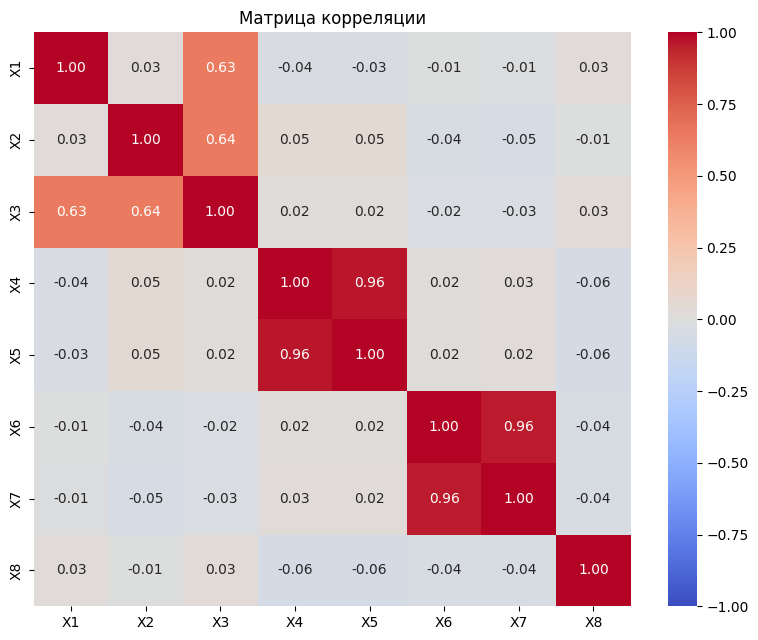

In [3]:
def mean(x):
    return np.sum(x, axis=0) / len(x)

def var(x):
    m = mean(x)
    return np.sum((x - m) ** 2, axis=0) / len(x)

def std(x):
    return var(x) ** 0.5

def corr_matrix(data):
    Z = (data - mean(data)) / std(data)
    return Z.T @ Z / len(data)

R = corr_matrix(X)

print("разница с np.corrcoef:", np.abs(R - np.corrcoef(X.T)).max())

plt.figure(figsize=(8, 6.5))
sns.heatmap(R, annot=True, fmt=".2f", xticklabels=df.columns, yticklabels=df.columns, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляции")
plt.tight_layout()
plt.show()

Реализовать алгоритм PCA на основе сингулярного разложения (SVD)

Готовый SVD использовать нельзя. Из работы с матрицами разрешены только сложение, умножение и создание единичной матрицы.

$$A = U \Sigma V^T$$

Столбцы $V$ - собственные векторы $A^T A$. Находим их степенным методом:

$$v \leftarrow \frac{Mv}{\lVert Mv \rVert}, \qquad M = A^T A$$

Потом считаем $\sigma = \lVert Av \rVert$ и $u = Av / \sigma$, снимаем найденный слой и повторяем:

$$A \leftarrow A - \sigma u v^T$$

In [4]:
def norm(v):
    return (v @ v) ** 0.5

def top_vector(M, tol=1e-12, max_iter=20000):
    v = np.random.rand(M.shape[0])
    v = v / norm(v)
    for _ in range(max_iter):
        w = M @ v
        w = w / norm(w)
        if norm(w - v) < tol:
            return w
        v = w
    return v

def svd(A, k):
    U, S, V = [], [], []
    for _ in range(k):
        v = top_vector(A.T @ A)
        s = norm(A @ v)
        u = A @ v / s
        A = A - s * np.outer(u, v)
        U.append(u)
        S.append(s)
        V.append(v)
    return np.array(U).T, np.array(S), np.array(V).T

A_small = np.array([[2., 1.], [1., 2.], [-1., -2.], [-2., -1.]])
U_small, S_small, V_small = svd(A_small, 2)

print("sigma:", S_small)
print("sigma^2:", S_small ** 2)
print(V_small)

sigma: [4.24264069 1.41421356]
sigma^2: [18.  2.]
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


PCA: центрируем данные, делаем SVD, проецируем на столбцы $V$

$$P = AV = U\Sigma, \qquad \lambda_i = \frac{\sigma_i^2}{N - 1}$$

In [5]:
def pca(data, k):
    m = mean(data)
    A = data - m
    U, S, V = svd(A, k)
    return A @ V, S ** 2 / (len(data) - 1), V, m

A = X - mean(X)
U, S, V = svd(A, 8)

print("sigma:", S.round(4))
print("np.linalg.svd:", np.linalg.svd(A, compute_uv=False).round(4))
print("|A - U S V^T|:", np.abs(A - U * S @ V.T).max())
print("|V^T V - I|:", np.abs(V.T @ V - np.eye(8)).max())
print("|U^T U - I|:", np.abs(U.T @ U - np.eye(8)).max())

sigma: [223.356  171.8265  90.8138  67.6872  37.6601  23.5328  15.7436   5.9105]
np.linalg.svd: [223.356  171.8265  90.8138  67.6872  37.6601  23.5328  15.7436   5.9105]
|A - U S V^T|: 7.105427357601002e-15
|V^T V - I|: 2.220446049250313e-16
|U^T U - I|: 7.267311752379157e-13


Найти проекцию датасета на 2-мерную систему координат

In [6]:
P, lam, V2, mean = pca(X, 2)

print("собственные значения:", lam)

pd.DataFrame(V2, index=df.columns, columns=["PC1", "PC2"]).round(3)

собственные значения: [49.93783244 29.55389659]


,PC1,PC2
X1,-0.010,0.362
X2,0.034,0.361
X3,0.033,0.859
X4,0.423,-0.018
X5,0.905,-0.032
X6,0.006,-0.013
X7,0.002,-0.005
X8,-0.004,0.003


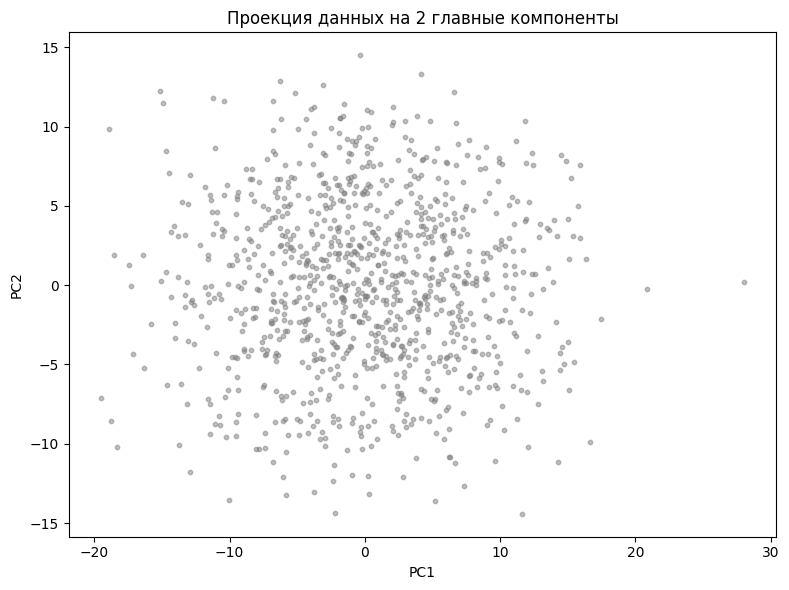

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(P[:, 0], P[:, 1], s=10, alpha=0.5, color="gray")
plt.title("Проекция данных на 2 главные компоненты")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

Найти ошибку проекции датасета

Восстанавливаем данные из проекции и смотрим, какая доля разброса потерялась:

$$\hat{A} = P V^T, \qquad error = \frac{\sum (A - \hat{A})^2}{\sum A^2} = \frac{\sum_{j > k} \lambda_j}{\sum_j \lambda_j}$$

In [8]:
def projection_error(data, k):
    P, _, V, mean = pca(data, k)
    A = data - mean
    return np.sum((A - P @ V.T) ** 2) / np.sum(A ** 2)

_, lam_all, _, _ = pca(X, 8)

print("ошибка на 2D:", projection_error(X, 2))
print("через собственные значения:", lam_all[2:].sum() / lam_all.sum())

ошибка на 2D: 0.15962168402943427
через собственные значения: 0.15962168402943422


Найти преобразование входных данных, при котором ошибка проекции будет оптимальной. Провести эксперимент по поиску числа компонент, при котором ошибка сжатия допустима

Сравним исходные данные и стандартизированные:

$$z = \frac{x - \bar{x}}{s}$$

Допустимой будем считать ошибку 5%.

In [9]:
Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0, ddof=1)

_, lam_raw, V_raw, _ = pca(X, 8)
_, lam_std, V_std, _ = pca(Z, 8)

err_raw = 1 - np.cumsum(lam_raw) / lam_raw.sum()
err_std = 1 - np.cumsum(lam_std) / lam_std.sum()

pd.DataFrame({
    "lambda": lam_raw, "ошибка": err_raw,
    "lambda (станд.)": lam_std, "ошибка (станд.)": err_std,
}, index=range(1, 9)).round(4)

,lambda,ошибка,lambda (станд.),ошибка (станд.)
1,49.9378,0.4721,2.0262,0.7467
2,29.5539,0.1596,1.9825,0.4989
3,8.2554,0.0723,1.8453,0.2683
4,4.5861,0.0239,0.9966,0.1437
5,1.4197,0.0089,0.9527,0.0246
6,0.5543,0.0030,0.1156,0.0102
7,0.2481,0.0004,0.0448,0.0045
8,0.0350,0.0000,0.0364,0.0000


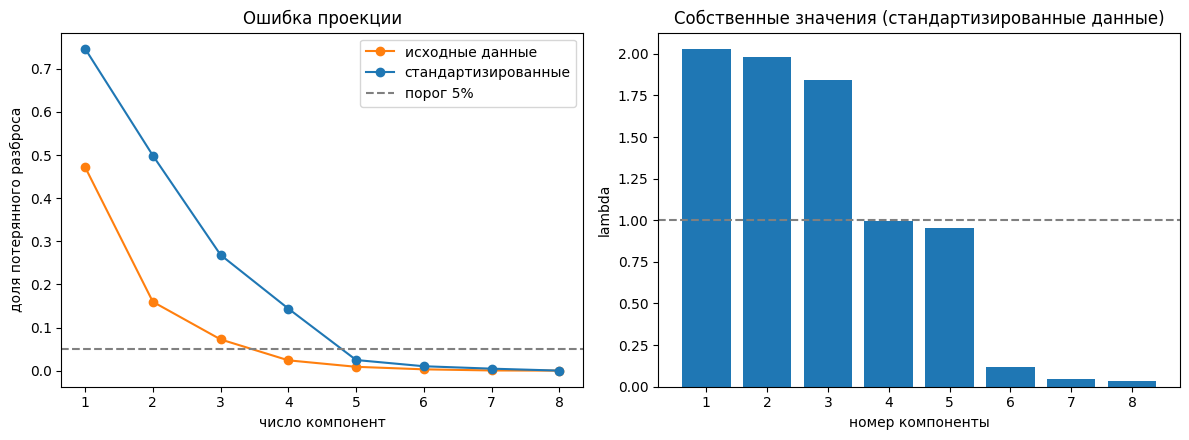

исходные: нужно компонент 4
стандартизированные: нужно компонент 5


In [10]:
ks = range(1, 9)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(ks, err_raw, "o-", color="tab:orange", label="исходные данные")
axes[0].plot(ks, err_std, "o-", color="tab:blue", label="стандартизированные")
axes[0].axhline(0.05, color="gray", linestyle="--", label="порог 5%")
axes[0].set_title("Ошибка проекции")
axes[0].set_xlabel("число компонент")
axes[0].set_ylabel("доля потерянного разброса")
axes[0].legend()

axes[1].bar(ks, lam_std, color="tab:blue")
axes[1].axhline(1, color="gray", linestyle="--")
axes[1].set_title("Собственные значения (стандартизированные данные)")
axes[1].set_xlabel("номер компоненты")
axes[1].set_ylabel("lambda")

plt.tight_layout()
plt.show()

print("исходные: нужно компонент", np.argmax(err_raw <= 0.05) + 1)
print("стандартизированные: нужно компонент", np.argmax(err_std <= 0.05) + 1)

Сколько разброса каждого признака осталось после сжатия: общая ошибка могла быть маленькой, а отдельный признак мог потеряться целиком

In [11]:
def kept_by_feature(data, k):
    P, _, V, mean = pca(data, k)
    A = data - mean
    return 1 - np.sum((A - P @ V.T) ** 2, axis=0) / np.sum(A ** 2, axis=0)

pd.DataFrame({
    "исходные, k=2": kept_by_feature(X, 2),
    "исходные, k=4": kept_by_feature(X, 4),
    "станд., k=2": kept_by_feature(Z, 2),
    "станд., k=5": kept_by_feature(Z, 5),
}, index=df.columns).round(3)

,"исходные, k=2","исходные, k=4","станд., k=2","станд., k=5"
X1,0.454,0.939,0.190,0.972
X2,0.458,0.938,0.305,0.971
X3,0.983,0.983,0.462,0.941
X4,0.952,0.952,0.853,0.982
X5,0.997,0.998,0.854,0.982
X6,0.002,0.999,0.658,0.978
X7,0.002,0.927,0.665,0.978
X8,0.005,0.007,0.022,1.000


In [12]:
pd.DataFrame(V_raw[:, :5], index=df.columns, columns=[f"PC{i}" for i in range(1, 6)]).round(2)

,PC1,PC2,PC3,PC4,PC5
X1,-0.01,0.36,-0.71,-0.04,0.61
X2,0.03,0.36,0.70,0.03,0.61
X3,0.03,0.86,-0.00,0.02,-0.51
X4,0.42,-0.02,-0.01,0.00,0.00
X5,0.90,-0.03,-0.03,-0.01,0.00
X6,0.01,-0.01,-0.05,0.95,0.02
X7,0.00,-0.00,-0.02,0.30,0.00
X8,-0.00,0.00,-0.00,-0.01,-0.02


In [13]:
pd.DataFrame(V_std[:, :5], index=df.columns, columns=[f"PC{i}" for i in range(1, 6)]).round(2)

,PC1,PC2,PC3,PC4,PC5
X1,-0.17,0.26,0.41,0.28,-0.65
X2,-0.14,0.36,0.32,-0.32,0.63
X3,-0.21,0.43,0.51,-0.01,-0.00
X4,0.41,0.51,-0.26,0.08,-0.03
X5,0.41,0.51,-0.26,0.08,-0.03
X6,0.53,-0.22,0.41,0.02,0.05
X7,0.53,-0.22,0.41,0.02,0.04
X8,-0.10,-0.03,0.03,0.90,0.43


Ошибка зависит от единиц измерения: запишем $X_8$ как 0 и 100 вместо 0 и 1

In [14]:
X_units = X.copy()
X_units[:, 7] = X_units[:, 7] * 100

_, lam_units, V_units, _ = pca(X_units, 2)

print("собственные значения:", lam_units)
print("первая компонента:", V_units[:, 0].round(3))
print("ошибка на 2D:", projection_error(X_units, 2))

собственные значения: [2502.69314496   49.7475146 ]
первая компонента: [ 0.002 -0.     0.003 -0.004 -0.008 -0.002 -0.001  1.   ]
ошибка на 2D: 0.017083303024337776


Вопросы 2 и 5. Нелинейные данные: точки лежат на кольце. По сути это одна величина, угол, но прямая её не опишет

собственные значения: [13.01545562 12.00933785]
ошибка при 1 компоненте: 0.47989758092093904
ошибка при 1 компоненте в полярных координатах: 0.00726380936216132


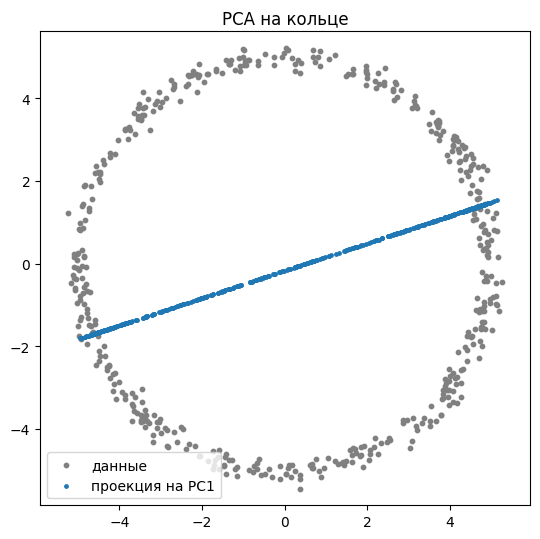

In [15]:
np.random.seed(42)

t = np.random.uniform(0, 2 * np.pi, 500)
r = 5 + np.random.normal(0, 0.15, 500)
ring = np.c_[r * np.cos(t), r * np.sin(t)]

P_ring, lam_ring, V_ring, mean_ring = pca(ring, 2)
line = P_ring[:, :1] @ V_ring[:, :1].T + mean_ring

print("собственные значения:", lam_ring)
print("ошибка при 1 компоненте:", projection_error(ring, 1))

polar = np.c_[np.hypot(ring[:, 0], ring[:, 1]), np.arctan2(ring[:, 1], ring[:, 0])]
print("ошибка при 1 компоненте в полярных координатах:", projection_error(polar, 1))

plt.figure(figsize=(5.5, 5.5))
plt.scatter(ring[:, 0], ring[:, 1], s=10, color="gray", label="данные")
plt.scatter(line[:, 0], line[:, 1], s=6, color="tab:blue", label="проекция на PC1")
plt.axis("equal")
plt.legend()
plt.title("PCA на кольце")
plt.tight_layout()
plt.show()

Вопросы 2 и 7. Выбросы: добавим 5 точек с огромным $X_6$ и посмотрим, куда повернётся первая компонента

In [16]:
bad = X[:5].copy()
bad[:, 5] = 100

X_bad = np.vstack([X, bad])
_, lam_bad, V_bad, _ = pca(X_bad, 2)

print("первая компонента без выбросов:", V2[:, 0].round(3))
print("первая компонента с выбросами:", V_bad[:, 0].round(3))
print("косинус угла между ними:", abs(V2[:, 0] @ V_bad[:, 0]))
print("собственные значения без выбросов:", lam[:2])
print("собственные значения с выбросами:", lam_bad)

первая компонента без выбросов: [-0.01   0.034  0.033  0.423  0.905  0.006  0.002 -0.004]
первая компонента с выбросами: [0.012 0.015 0.027 0.027 0.064 0.997 0.023 0.004]
косинус угла между ними: 0.07596317359284525
собственные значения без выбросов: [49.93783244 29.55389659]
собственные значения с выбросами: [51.83121563 50.24131273]


Вопрос 6. Что теряется при малом числе компонент: сожмём картинки рукописных цифр 8x8 (64 признака) и восстановим обратно

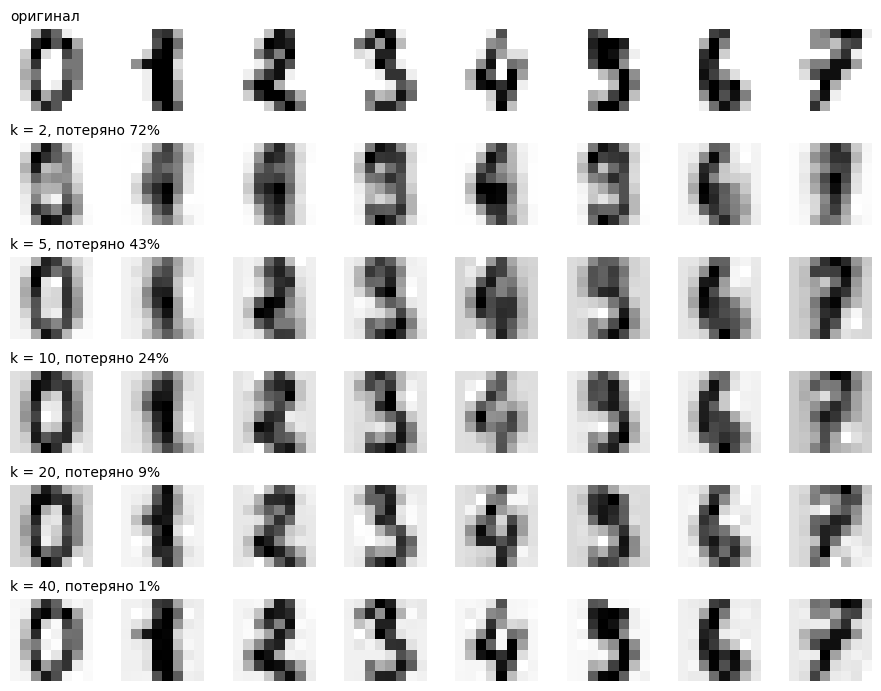

In [17]:
from sklearn.datasets import load_digits

digits = load_digits().data[:600]

np.random.seed(42)
P_d, lam_d, V_d, mean_d = pca(digits, 40)

total_d = np.sum((digits - mean_d) ** 2) / (len(digits) - 1)
counts = [2, 5, 10, 20, 40]

fig, axes = plt.subplots(len(counts) + 1, 8, figsize=(9, 7))

for j in range(8):
    axes[0, j].imshow(digits[j].reshape(8, 8), cmap="gray_r")
    for i, k in enumerate(counts):
        restored = P_d[:, :k] @ V_d[:, :k].T + mean_d
        axes[i + 1, j].imshow(restored[j].reshape(8, 8), cmap="gray_r")

axes[0, 0].set_title("оригинал", loc="left", fontsize=10)
for i, k in enumerate(counts):
    axes[i + 1, 0].set_title(f"k = {k}, потеряно {1 - lam_d[:k].sum() / total_d:.0%}", loc="left", fontsize=10)

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

Вопрос 8. PCA перед обучением модели: предсказываем $y$ линейной регрессией по компонентам

Среднее, отклонение и компоненты считаем только на обучающей части, тестовую просто пропускаем через готовое преобразование

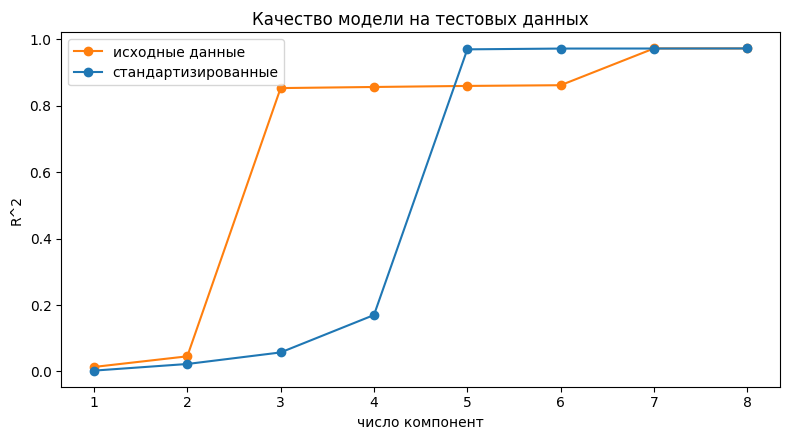

,R^2 исходные,R^2 станд.
k,,
1,0.0137,0.0027
2,0.0457,0.0226
3,0.8536,0.0574
4,0.8569,0.1701
5,0.8601,0.9703
6,0.8622,0.9726
7,0.9730,0.9728
8,0.9730,0.9730


In [18]:
from sklearn.linear_model import LinearRegression

np.random.seed(42)

y = 3 * X1 - 2 * X2 + X4 + 0.5 * X6 + 8 * X8 + np.random.normal(0, 2, N)

train, test = np.arange(800), np.arange(800, N)

def score(data, k, scale):
    mean = np.mean(data[train], axis=0)
    std = np.std(data[train], axis=0, ddof=1) if scale else 1
    A = (data - mean) / std
    _, _, V = svd(A[train], k)
    model = LinearRegression().fit(A[train] @ V, y[train])
    return model.score(A[test] @ V, y[test])

rows = [[k, score(X, k, False), score(X, k, True)] for k in ks]
scores = pd.DataFrame(rows, columns=["k", "R^2 исходные", "R^2 станд."]).set_index("k")

plt.figure(figsize=(8, 4.5))
plt.plot(scores.index, scores["R^2 исходные"], "o-", color="tab:orange", label="исходные данные")
plt.plot(scores.index, scores["R^2 станд."], "o-", color="tab:blue", label="стандартизированные")
plt.title("Качество модели на тестовых данных")
plt.xlabel("число компонент")
plt.ylabel("R^2")
plt.legend()
plt.tight_layout()
plt.show()

scores.round(4)